In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('train_digit.csv')
df.sample(8)

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
26747,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
30119,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4330,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
16179,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2781,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
17250,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6229,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
30814,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
df.shape

(42000, 785)

# Without PCA

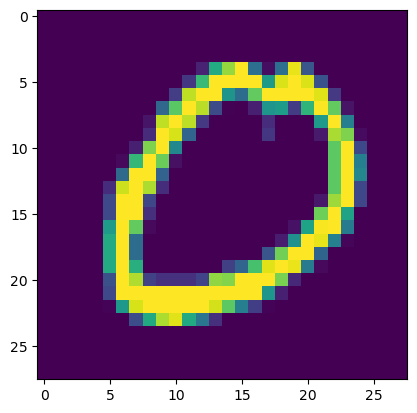

In [7]:
plt.imshow(df.iloc[13051, 1:].values.reshape(28, 28))

In [9]:
x = df.iloc[:, 1:]
y = df.iloc[:, 0]

In [11]:
from sklearn.model_selection import train_test_split

In [13]:
x_train, x_test, y_train, y_test = train_test_split(x,
                                                    y,
                                                    test_size = 0.2,
                                                    random_state=42)

In [15]:
x_train.shape

(33600, 784)

In [17]:
from sklearn.neighbors import KNeighborsClassifier

In [19]:
knn = KNeighborsClassifier()

In [21]:
knn.fit(x_train, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [23]:
import time
start = time.time()
y_pred = knn.predict(x_test)
print(time.time() - start)

5.493373155593872


In [25]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.9648809523809524

# With PCA

In [27]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [29]:
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [31]:
# PCA
from sklearn.decomposition import PCA
pca = PCA(n_components=200)

In [33]:
x_train_trf = pca.fit_transform(x_train)
x_test_trf = pca.transform(x_test)

In [35]:
x_train.shape


(33600, 784)

In [37]:
x_train_trf.shape

(33600, 200)

In [39]:
knn = KNeighborsClassifier()

In [41]:
knn.fit(x_train_trf, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [43]:
y_pred = knn.predict(x_test_trf)
accuracy_score(y_test, y_pred)

0.9507142857142857

In [45]:
x_train.shape

(33600, 784)

In [47]:
lis = [0]
for i in range(1, 170):
    pca = PCA(n_components=i)
    x_train_trf = pca.fit_transform(x_train)
    x_test_trf = pca.transform(x_test)

    knn = KNeighborsClassifier() 
    knn.fit(x_train_trf, y_train)
    

    y_pred = knn.predict(x_test_trf)
    lis.append(accuracy_score(y_test, y_pred))

In [49]:
lis

[0,
 0.2580952380952381,
 0.3236904761904762,
 0.5104761904761905,
 0.6663095238095238,
 0.7378571428571429,
 0.8227380952380953,
 0.8436904761904762,
 0.8721428571428571,
 0.886547619047619,
 0.9055952380952381,
 0.9116666666666666,
 0.9184523809523809,
 0.9276190476190476,
 0.9351190476190476,
 0.9384523809523809,
 0.9379761904761905,
 0.9407142857142857,
 0.94,
 0.9425,
 0.9442857142857143,
 0.9438095238095238,
 0.9441666666666667,
 0.9442857142857143,
 0.9457142857142857,
 0.9484523809523809,
 0.9479761904761905,
 0.9478571428571428,
 0.9471428571428572,
 0.949047619047619,
 0.9491666666666667,
 0.9507142857142857,
 0.9513095238095238,
 0.95,
 0.9504761904761905,
 0.950952380952381,
 0.9519047619047619,
 0.9517857142857142,
 0.9527380952380953,
 0.9533333333333334,
 0.9528571428571428,
 0.9522619047619048,
 0.9522619047619048,
 0.9523809523809523,
 0.9533333333333334,
 0.9528571428571428,
 0.9530952380952381,
 0.9530952380952381,
 0.9533333333333334,
 0.9527380952380953,
 0.9533333

In [51]:
max(lis)

0.9557142857142857

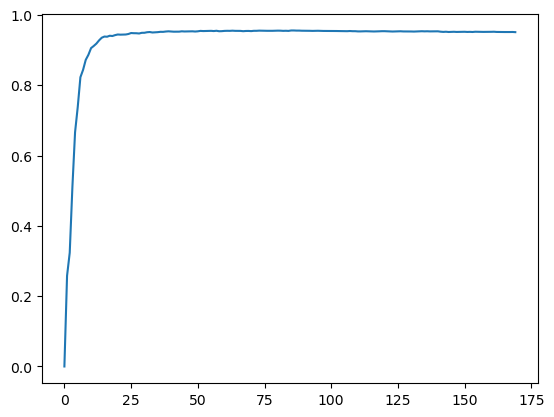

In [53]:
plt.plot(lis)

In [55]:
# Transforming to a 2D coordinate system
pca = PCA(n_components=2)
x_train_trf = pca.fit_transform(x_train)
x_test_trf = pca.transform(x_test)

x_train_trf

array([[-2.71863253, -0.48982409],
       [-0.67698015, -6.75362491],
       [-3.03323281,  6.50981624],
       ...,
       [ 2.14883643,  0.78079444],
       [ 1.05957006,  0.94767312],
       [17.70258446,  1.96188185]])

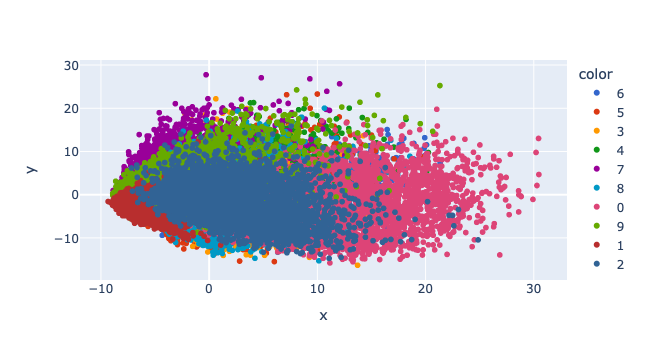

In [57]:
# in 2D
import plotly.express as px
y_train_trf = y_train.astype(str)
fig = px.scatter( x=x_train_trf[:, 0],
                y = x_train_trf[:, 1],
                color = y_train_trf,
                color_discrete_sequence=px.colors.qualitative.G10
                )

fig.show()

In [59]:
# in 3D
pca = PCA(n_components=3)
x_train_trf = pca.fit_transform(x_train)
x_test_trf = pca.transform(x_test)

x_train_trf

array([[-2.71863253, -0.48982409,  1.1354966 ],
       [-0.67698015, -6.75362491, -2.33590139],
       [-3.03323281,  6.50981624,  7.49182983],
       ...,
       [ 2.14883643,  0.78079444, -0.74738774],
       [ 1.05957006,  0.94767312,  3.94973114],
       [17.70258446,  1.96188185, -4.94352837]])

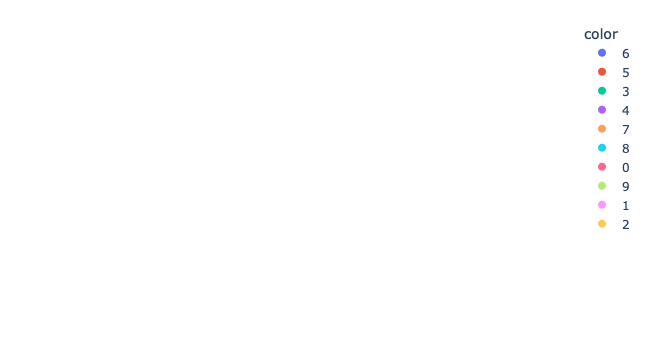

In [61]:
y_train_trf = y_train.astype(str)
fig = px.scatter_3d(df,
                    x = x_train_trf[:, 0],
                    y = x_train_trf[:, 1],
                    z = x_train_trf[:, 2],
                    color = y_train_trf
                   )

fig.update_layout(
    margin=dict(l=20, r=20, t=20, b=20)
)

fig.show()

In [63]:
# Eigen values
pca.explained_variance_

array([40.67111198, 29.17023401, 26.74459621])

In [65]:
# Eigen vectors
pca.components_.shape

(3, 784)

# Finding Optimum Number of PC's

No need to use the loop to find the optimal number of components.

## Remember! Eigen value tell us how much info is preserved.

percentage an eigen value preserve the info :- 

## $𝜆i X 100$
##  _______
## $(⨊ 𝜆i)$
p
keep that much till where summation reaches 95 or above,
means we are loosing only 5% of the information.

In [68]:
(pca.explained_variance_ratio_)*100

array([5.78519225, 4.14926968, 3.80423901])

In [70]:
# in 3D
pca = PCA(n_components=None)
x_train_trf = pca.fit_transform(x_train)
x_test_trf = pca.transform(x_test)


In [82]:
pca.explained_variance_ratio_

array([5.78519225e-02, 4.14926968e-02, 3.80423901e-02, 2.96626277e-02,
       2.58156168e-02, 2.25498018e-02, 1.97306802e-02, 1.77527998e-02,
       1.56865066e-02, 1.43606328e-02, 1.37025484e-02, 1.22725500e-02,
       1.14691200e-02, 1.12302739e-02, 1.05852885e-02, 1.01993106e-02,
       9.57676152e-03, 9.42708817e-03, 9.12489429e-03, 8.90170190e-03,
       8.39940495e-03, 8.20063196e-03, 7.85303229e-03, 7.56739707e-03,
       7.37261022e-03, 7.01884653e-03, 6.97919728e-03, 6.71104483e-03,
       6.39845030e-03, 6.30337291e-03, 6.15350848e-03, 6.02388659e-03,
       5.83673972e-03, 5.78547759e-03, 5.72333148e-03, 5.46399774e-03,
       5.43207369e-03, 5.28172755e-03, 5.13381744e-03, 4.94015474e-03,
       4.87671103e-03, 4.81978768e-03, 4.68204430e-03, 4.59342487e-03,
       4.57660834e-03, 4.49219022e-03, 4.44682221e-03, 4.41540749e-03,
       4.35111936e-03, 4.32032928e-03, 4.21808870e-03, 4.18243127e-03,
       4.07994349e-03, 4.02004913e-03, 3.98335855e-03, 3.94598812e-03,
      

In [74]:
x = np.cumsum((pca.explained_variance_ratio_)*100)

<IPython.core.display.Javascript object>

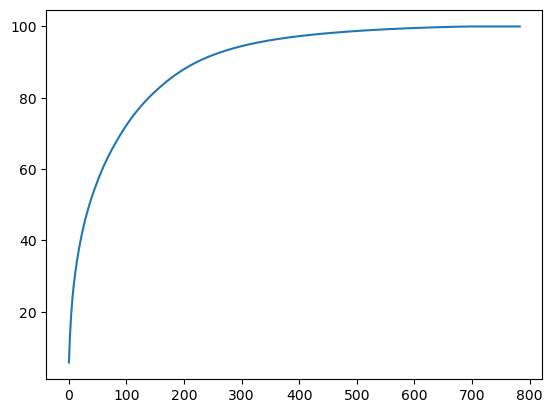

In [78]:
plt.plot(x)